# 01 — Data description, EDA, missing values and baseline
**Competition:** [House Prices – Advanced Regression Techniques](https://www.kaggle.com/competitions/house-prices-advanced-regression-techniques)
**Author of this notebook:** Kofi Opoku Ayim (team: Majba ull Alam Akash, Kofi Opoku Ayim, Omisore Omolola Bimpe)

**Task.** Predict the sale price (`SalePrice`, US dollars) of houses in Ames, Iowa from 79 features.
**Metric.** RMSE between log(predicted price) and log(actual price): errors are measured *relative* to the price,
so the same dollar error costs more on a cheap house than on an expensive one.

## 0. Setup and data
In Colab: run the next cell and upload `train.csv` and `test.csv` (from the competition's *Data* tab).

In [1]:
import os
from pathlib import Path
if not (Path("train.csv").exists() and Path("test.csv").exists()):
    try:
        from google.colab import files
        files.upload()          # choose train.csv and test.csv
    except ImportError:
        print("Put train.csv and test.csv next to this notebook.")
print(sorted(p.name for p in Path(".").glob("*.csv")))

['test.csv', 'train.csv']


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import KFold

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)
SEED = 42
FIG = Path("figures"); FIG.mkdir(exist_ok=True)
def save(fig, name):
    fig.tight_layout(); fig.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")

train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")

## 1. Data description

In [3]:
print(f"train: {train.shape[0]} rows x {train.shape[1]} columns")
print(f"test:  {test.shape[0]} rows x {test.shape[1]} columns")
print("only in train:", sorted(set(train.columns) - set(test.columns)))
num_cols = [c for c in train.select_dtypes(include=np.number).columns if c not in ("Id", "SalePrice")]
cat_cols = [c for c in train.columns if c not in num_cols + ["Id", "SalePrice"]]
print(f"numeric features: {len(num_cols)} | categorical features: {len(cat_cols)}")
train.head()

train: 1460 rows x 81 columns
test:  1459 rows x 80 columns
only in train: ['SalePrice']
numeric features: 36 | categorical features: 43


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


The most important features (full list: `data_description.txt` on the competition page):

In [4]:
meaning = {
    "OverallQual": ("ordinal 1–10", "overall material and finish quality"),
    "GrLivArea": ("numeric, sq ft", "above-ground living area"),
    "TotalBsmtSF": ("numeric, sq ft", "total basement area"),
    "1stFlrSF": ("numeric, sq ft", "first floor area"),
    "GarageCars": ("discrete", "garage size in car capacity"),
    "GarageArea": ("numeric, sq ft", "garage area"),
    "YearBuilt": ("numeric, year", "original construction year"),
    "YearRemodAdd": ("numeric, year", "remodel year (= YearBuilt if never remodelled)"),
    "FullBath": ("discrete", "full bathrooms above ground"),
    "TotRmsAbvGrd": ("discrete", "rooms above ground (no bathrooms)"),
    "LotArea": ("numeric, sq ft", "lot size"),
    "Neighborhood": ("categorical, 25 levels", "location within Ames"),
    "MSZoning": ("categorical", "zoning class (residential density, commercial, ...)"),
    "KitchenQual": ("ordinal Po–Ex", "kitchen quality"),
    "ExterQual": ("ordinal Po–Ex", "exterior material quality"),
    "SaleCondition": ("categorical", "normal sale, foreclosure, family sale, partial (new house), ..."),
    "SalePrice": ("numeric, USD", "TARGET: sale price"),
}
pd.DataFrame(meaning, index=["type", "meaning"]).T.assign(
    dtype=lambda d: [str(train[c].dtype) for c in d.index],
    n_unique=lambda d: [train[c].nunique() for c in d.index],
    missing=lambda d: [int(train[c].isna().sum()) for c in d.index])

,type,meaning,dtype,n_unique,missing
OverallQual,ordinal 1–10,overall material and finish quality,int64,10,0
GrLivArea,"numeric, sq ft",above-ground living area,int64,861,0
TotalBsmtSF,"numeric, sq ft",total basement area,int64,721,0
1stFlrSF,"numeric, sq ft",first floor area,int64,753,0
GarageCars,discrete,garage size in car capacity,int64,5,0
GarageArea,"numeric, sq ft",garage area,int64,441,0
YearBuilt,"numeric, year",original construction year,int64,112,0
YearRemodAdd,"numeric, year",remodel year (= YearBuilt if never remodelled),int64,61,0
FullBath,discrete,full bathrooms above ground,int64,4,0
TotRmsAbvGrd,discrete,rooms above ground (no bathrooms),int64,12,0


**Findings.** The training set has 1,460 houses and the test set 1,459, so both are almost the same size. Each house is
described by 79 features: 36 numeric and 43 categorical. The only column missing from the test set is the target
`SalePrice`. None of the 17 key features above has missing values in train. Because almost half of the features are
categorical (e.g. `Neighborhood` with 25 values), they have to be encoded before modelling.

## 2. Target distribution

count      1460.0
mean     180921.0
std       79443.0
min       34900.0
25%      129975.0
50%      163000.0
75%      214000.0
max      755000.0
Name: SalePrice, dtype: float64
skewness: raw 1.88 | log 0.12


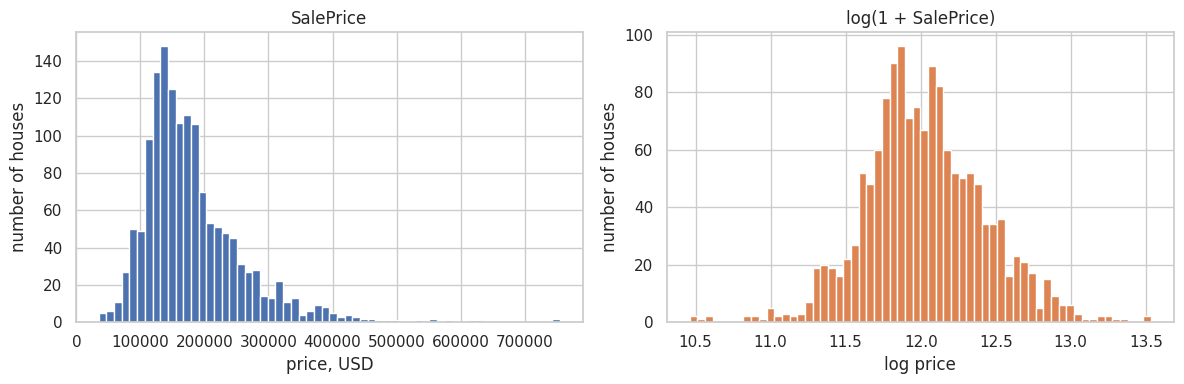

In [5]:
y = train["SalePrice"]
print(y.describe().round(0))
print(f"skewness: raw {y.skew():.2f} | log {np.log1p(y).skew():.2f}")
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(y, bins=60, color="#4C72B0"); ax[0].set(title="SalePrice", xlabel="price, USD", ylabel="number of houses")
ax[1].hist(np.log1p(y), bins=60, color="#DD8452"); ax[1].set(title="log(1 + SalePrice)", xlabel="log price", ylabel="number of houses")
save(fig, "01_target"); plt.show()

**Findings.** The sale price is right-skewed (skewness 1.88): the median house costs \$163,000, but the mean is higher
(\$180,921) because a few very expensive houses pull it up; prices range from \$34,900 to \$755,000, and half of all houses
sell between \$130,000 and \$214,000. After the log transform the distribution is almost symmetric (skewness 0.12).
Since the competition metric is RMSE on log prices, training on log(SalePrice) optimises exactly what is scored and
prevents the few expensive houses from dominating the error.

## 3. Distributions of the main features
### 3.1 Numeric features (histograms)

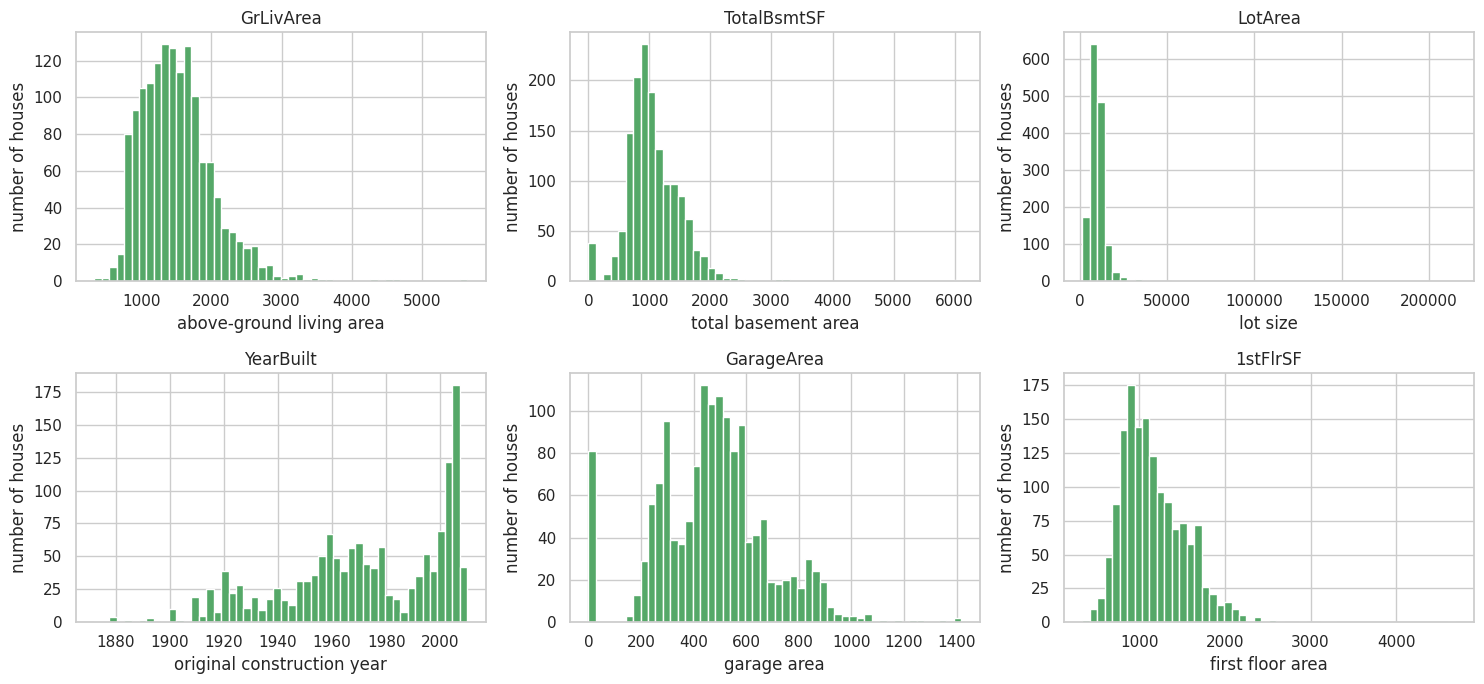

,count,mean,std,min,25%,50%,75%,max
GrLivArea,1460.0,1515.5,525.5,334.0,1129.5,1464.0,1776.8,5642.0
TotalBsmtSF,1460.0,1057.4,438.7,0.0,795.8,991.5,1298.2,6110.0
LotArea,1460.0,10516.8,9981.3,1300.0,7553.5,9478.5,11601.5,215245.0
YearBuilt,1460.0,1971.3,30.2,1872.0,1954.0,1973.0,2000.0,2010.0
GarageArea,1460.0,473.0,213.8,0.0,334.5,480.0,576.0,1418.0
1stFlrSF,1460.0,1162.6,386.6,334.0,882.0,1087.0,1391.2,4692.0


In [6]:
main_num = ["GrLivArea", "TotalBsmtSF", "LotArea", "YearBuilt", "GarageArea", "1stFlrSF"]
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, c in zip(axes.ravel(), main_num):
    ax.hist(train[c].dropna(), bins=50, color="#55A868")
    ax.set(title=c, xlabel=meaning.get(c, ("", c))[1], ylabel="number of houses")
save(fig, "01_numeric_features"); plt.show()
train[main_num].describe().T.round(1)

**Findings.** All area features are right-skewed with a few extreme values: `LotArea` has a median of 9,479 sq ft but a
maximum of 215,245, and `GrLivArea` goes up to 5,642 sq ft (median 1,464). `TotalBsmtSF` and `GarageArea` have a minimum
of 0: these houses have no basement or no garage, which is information, not an error. Houses were built between 1872
and 2010 (median 1973), with many built in the 1950s–70s and a building boom around 2000–2007. The skewed area
features are a reason to use log / Box-Cox transforms for linear models.

### 3.2 Categorical features (bar charts)

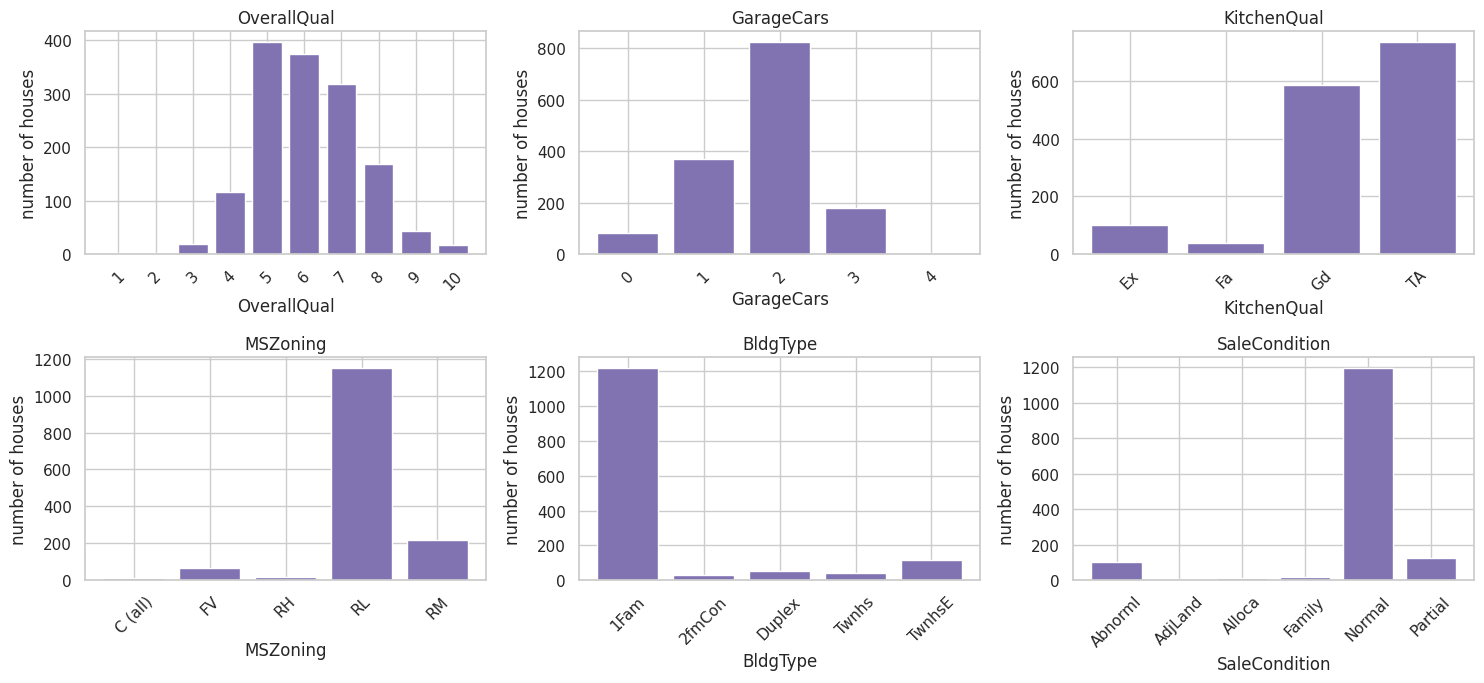

In [7]:
main_cat = ["OverallQual", "GarageCars", "KitchenQual", "MSZoning", "BldgType", "SaleCondition"]
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, c in zip(axes.ravel(), main_cat):
    vc = train[c].value_counts().sort_index()
    ax.bar(vc.index.astype(str), vc.values, color="#8172B2")
    ax.set(title=c, xlabel=c, ylabel="number of houses")
    ax.tick_params(axis="x", rotation=45)
save(fig, "01_categorical_features"); plt.show()

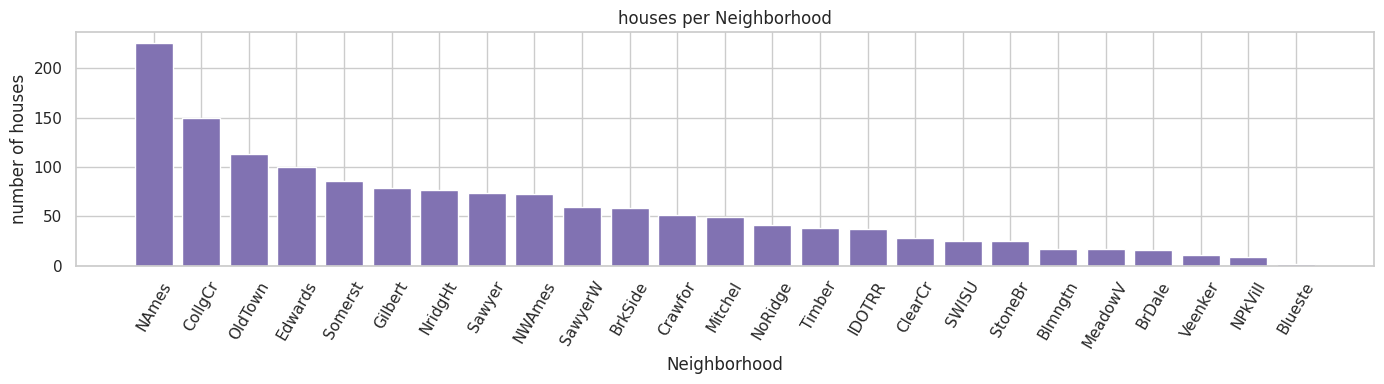

In [8]:
fig, ax = plt.subplots(figsize=(14, 4))
vc = train["Neighborhood"].value_counts()
ax.bar(vc.index, vc.values, color="#8172B2")
ax.set(title="houses per Neighborhood", xlabel="Neighborhood", ylabel="number of houses")
ax.tick_params(axis="x", rotation=60)
save(fig, "01_neighborhood_counts"); plt.show()

**Findings.** Most houses are of average quality (OverallQual 5–6); very poor (1–2) and top (10) quality are rare. A
2-car garage is by far the most common. Most houses are in low-density residential zoning (RL), are single-family
houses (1Fam) and were sold under normal conditions; partial sales (new houses) and abnormal sales (e.g. foreclosures)
are the main exceptions. Several categories have only a handful of houses (e.g. commercial zoning, some building
types, some neighborhoods), which makes their effect hard to estimate reliably.

## 4. Relations between the features and the target

In [9]:
logp = np.log1p(train["SalePrice"])
corr = train[num_cols].corrwith(logp).sort_values(ascending=False)
print("correlation with log(SalePrice), top 10:"); print(corr.head(10).round(3))
print("\nmost negative:"); print(corr.tail(5).round(3))

correlation with log(SalePrice), top 10:
OverallQual     0.817
GrLivArea       0.701
GarageCars      0.681
GarageArea      0.651
TotalBsmtSF     0.612
1stFlrSF        0.597
FullBath        0.595
YearBuilt       0.587
YearRemodAdd    0.566
GarageYrBlt     0.541
dtype: float64

most negative:
YrSold          -0.037
LowQualFinSF    -0.038
MSSubClass      -0.074
KitchenAbvGr    -0.148
EnclosedPorch   -0.149
dtype: float64


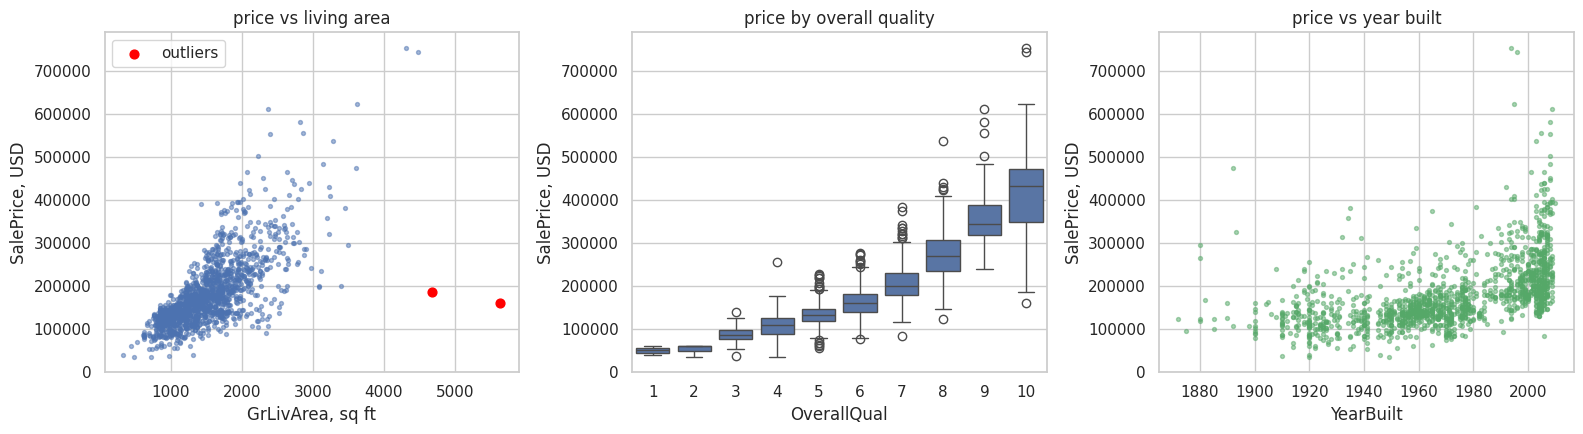

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
axes[0].scatter(train["GrLivArea"], train["SalePrice"], s=8, alpha=0.5)
out = (train["GrLivArea"] > 4000) & (train["SalePrice"] < 300000)
axes[0].scatter(train.loc[out, "GrLivArea"], train.loc[out, "SalePrice"], s=40, color="red", label="outliers")
axes[0].set(title="price vs living area", xlabel="GrLivArea, sq ft", ylabel="SalePrice, USD"); axes[0].legend()
sns.boxplot(x=train["OverallQual"], y=train["SalePrice"], ax=axes[1], color="#4C72B0")
axes[1].set(title="price by overall quality", xlabel="OverallQual", ylabel="SalePrice, USD")
axes[2].scatter(train["YearBuilt"], train["SalePrice"], s=8, alpha=0.5, color="#55A868")
axes[2].set(title="price vs year built", xlabel="YearBuilt", ylabel="SalePrice, USD")
save(fig, "01_relations"); plt.show()

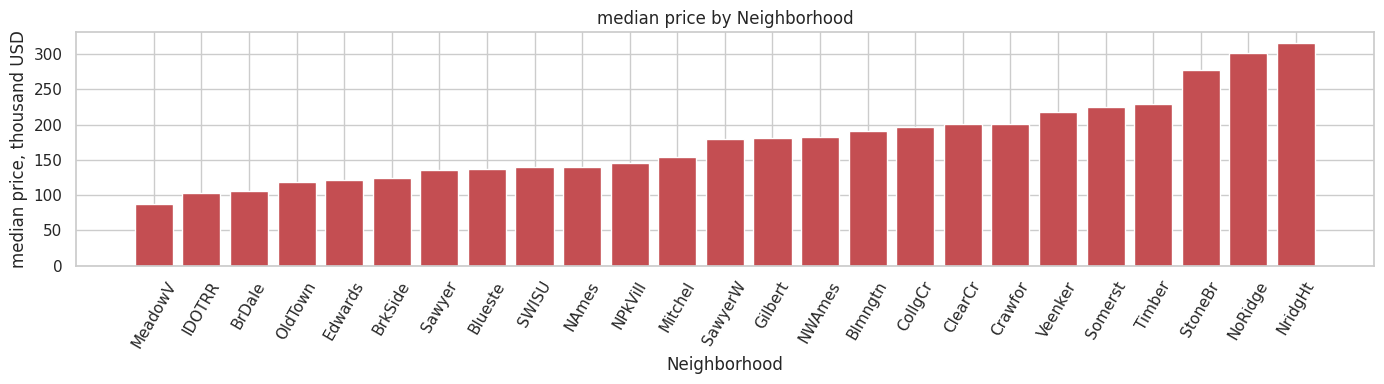

In [11]:
med = train.groupby("Neighborhood")["SalePrice"].median().sort_values()
fig, ax = plt.subplots(figsize=(14, 4))
ax.bar(med.index, med.values / 1000, color="#C44E52")
ax.set(title="median price by Neighborhood", xlabel="Neighborhood", ylabel="median price, thousand USD")
ax.tick_params(axis="x", rotation=60)
save(fig, "01_price_by_neighborhood"); plt.show()

**Findings.** The features most related to log price are overall quality (correlation 0.82), living area (0.70), garage
size (GarageCars 0.68, GarageArea 0.65), basement and first-floor area (about 0.6), full bathrooms (0.60) and year built
(0.59). Price grows faster than linearly with quality: each step up in OverallQual adds more dollars than the previous
one. Location matters a lot: median prices differ roughly threefold between the cheapest and the most expensive
neighborhoods. The red points are two very large houses (4,676 and 5,642 sq ft) sold far below the trend.

## 5. Missing values

In [12]:
miss = pd.DataFrame({
    "missing_train": train.isna().sum(),
    "missing_test": test.isna().sum().reindex(train.columns),
}).fillna(0).astype(int)
miss["share_train_%"] = (100 * miss["missing_train"] / len(train)).round(1)
miss = miss[(miss.missing_train > 0) | (miss.missing_test > 0)].sort_values("missing_train", ascending=False)
print(f"{len(miss)} columns have missing values")
miss

34 columns have missing values


,missing_train,missing_test,share_train_%
PoolQC,1453,1456,99.5
MiscFeature,1406,1408,96.3
Alley,1369,1352,93.8
Fence,1179,1169,80.8
MasVnrType,872,894,59.7
FireplaceQu,690,730,47.3
LotFrontage,259,227,17.7
GarageYrBlt,81,78,5.5
GarageFinish,81,78,5.5
GarageCond,81,78,5.5


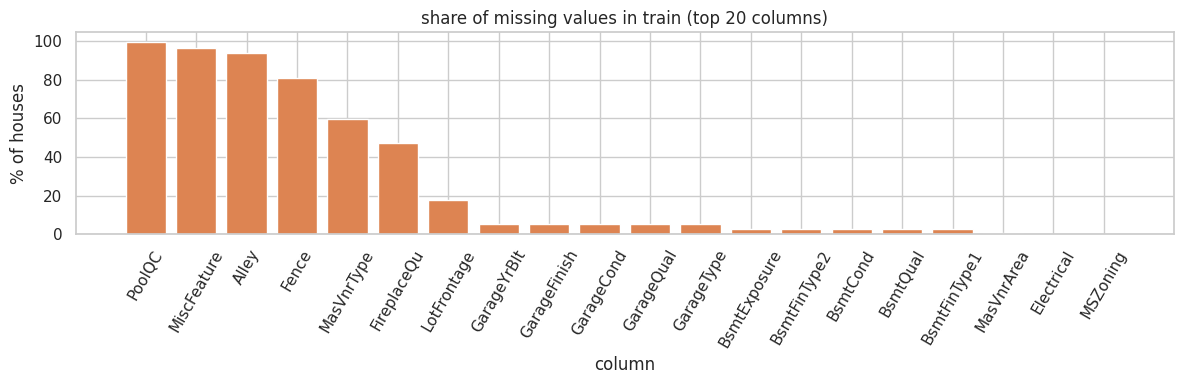

In [13]:
fig, ax = plt.subplots(figsize=(12, 4))
top = miss.head(20)
ax.bar(top.index, top["share_train_%"], color="#DD8452")
ax.set(title="share of missing values in train (top 20 columns)", xlabel="column", ylabel="% of houses")
ax.tick_params(axis="x", rotation=60)
save(fig, "01_missing_values"); plt.show()

Two kinds of missing values (see `data_description.txt`):
* **"NA means the feature does not exist"**: `PoolQC`, `MiscFeature`, `Alley`, `Fence`, `FireplaceQu`, garage and
  basement columns. Handling: fill with `"None"` (categorical) or `0` (areas, counts). Dropping these houses would
  throw away most of the data, and "no pool" is real information.
* **Truly unknown values**: `LotFrontage` (~18%), a few in `MasVnrType/MasVnrArea`, `Electrical`, and some test
  columns. Handling: `LotFrontage` = median of the same neighborhood (similar streets), the rest = most frequent value.

**Findings.** 34 columns have missing values in train or test. `PoolQC` (99.5%), `MiscFeature` (96.3%), `Alley` (93.8%) and
`Fence` (80.8%) are almost entirely missing, because most houses have no pool, extra feature, alley access or fence.
`MasVnrType` shows 872 missing values because pandas reads the value "None" (no masonry veneer) as missing; it is the
same "does not exist" case. The test set has missing values in 15 columns that are complete in train (e.g. `MSZoning`,
`KitchenQual`, `GarageCars`, `SaleType`, 1–4 houses each), so the filling rules must also work for test. Dropping rows
is not an option: almost every house has at least one missing value, and test rows can never be dropped.

## 6. Outliers and other data problems

In [14]:
print("houses with GrLivArea > 4000 sq ft:")
print(train.loc[train["GrLivArea"] > 4000, ["Id", "GrLivArea", "SalePrice", "OverallQual", "SaleCondition"]])
print("\nUtilities values in train:", train["Utilities"].value_counts().to_dict())

houses with GrLivArea > 4000 sq ft:
        Id  GrLivArea  SalePrice  OverallQual SaleCondition
523    524       4676     184750           10       Partial
691    692       4316     755000           10        Normal
1182  1183       4476     745000           10       Abnorml
1298  1299       5642     160000           10       Partial

Utilities values in train: {'AllPub': 1459, 'NoSeWa': 1}


**Findings.** Four houses have more than 4,000 sq ft of living area. Two of them (Id 524 and 1299, 4,676 and 5,642 sq ft)
sold for only \$184,750 and \$160,000, far below the trend; both are *Partial* sales, so the price probably does not
reflect a finished house on the open market. They are removed from training because they would pull the models in the
wrong direction. The other two large houses sold for \$755,000 and \$745,000, in line with their size and quality, so they
are kept. `Utilities` is "AllPub" for all houses except one, so it carries no information and is dropped.

## 7. Baseline (trivial predictions)
Same validation as in Akash's notebook: 5-fold cross-validation (`KFold(5, shuffle=True, random_state=42)`) and
RMSE on log prices. Every "model" below is fitted only on the training folds.

In [15]:
kf = KFold(5, shuffle=True, random_state=SEED)
def cv_rmse(fit_predict):
    scores = []
    for tr_idx, va_idx in kf.split(train):
        tr, va = train.iloc[tr_idx], train.iloc[va_idx]
        pred = fit_predict(tr, va)
        scores.append(np.sqrt(np.mean((pred - np.log1p(va["SalePrice"])) ** 2)))
    return np.mean(scores), np.std(scores)

def constant_mean(tr, va):          # best constant for RMSE on the log scale
    return np.full(len(va), np.log1p(tr["SalePrice"]).mean())

def median_by_quality(tr, va):      # simple rule: median log price of houses with the same OverallQual
    m = np.log1p(tr["SalePrice"]).groupby(tr["OverallQual"]).median()
    return va["OverallQual"].map(m).fillna(np.log1p(tr["SalePrice"]).median()).to_numpy()

def median_by_neighborhood(tr, va):
    m = np.log1p(tr["SalePrice"]).groupby(tr["Neighborhood"]).median()
    return va["Neighborhood"].map(m).fillna(np.log1p(tr["SalePrice"]).median()).to_numpy()

baselines = pd.DataFrame(
    [(name, *cv_rmse(f)) for name, f in [("constant (mean log price)", constant_mean),
                                         ("rule: median by OverallQual", median_by_quality),
                                         ("rule: median by Neighborhood", median_by_neighborhood)]],
    columns=["baseline", "CV RMSE (log)", "std"]).round(4)
baselines.to_csv("baselines.csv", index=False)
baselines

,baseline,CV RMSE (log),std
0,constant (mean log price),0.3988,0.0251
1,rule: median by OverallQual,0.2305,0.0090
2,rule: median by Neighborhood,0.2690,0.0094


**Comparison with the models.** The trivial constant prediction (the mean log price) gives a CV RMSE of 0.3988.
Simple rules already help a lot: the median price of houses with the same OverallQual gives 0.2305, and the median by
Neighborhood gives 0.2690, so quality and location alone explain a large part of the price. The models in
`House_Price_2.ipynb`, which use all features, reach 0.111–0.113 individually and 0.1063 with the stacking blend: about
3.7 times lower error than the constant and about half the error of the best simple rule. The difference is the value
added by combining many features (living area, basement, garage, age) instead of a single one.

## 8. Summary of the EDA
* The price is right-skewed (median \$163,000, max \$755,000); on the log scale it is almost normal, which matches the
  competition metric, so all models use log(SalePrice).
* Quality and size drive the price: OverallQual (0.82), GrLivArea (0.70) and garage size are the strongest features;
  location adds a lot (about 3× between neighborhoods).
* 34 columns have missing values, but most of them mean "the house does not have this" (no pool, fence, garage,
  basement) and are filled with "None" or 0; `LotFrontage` is filled with the neighborhood median.
* Two huge but cheap partial sales are outliers and are removed from training; `Utilities` is almost constant.
* Baselines: constant 0.3988, best simple rule 0.2305; the final models reach 0.1063.